# TP — El Niño : diagnostic, nettoyage et préparation des données NOAA

**Nexa Digital School — Jour 1 · Feature Engineering & Explicabilité**

Objectif : transformer la série brute des anomalies de température de surface de la région **Niño 3.4**
(NOAA PSL) en un jeu de données **fiable, cohérent, documenté et réutilisable**. Il ne s'agit pas de prédire El Niño.

> **Source des données.** Le notebook tente d'abord de lire le fichier officiel
> `https://psl.noaa.gov/data/correlation/nina34.anom.csv`. Si l'URL n'est pas accessible (pas de réseau,
> pare-feu…), il utilise l'extrait fourni avec le TP : `data/extrait_noaa_1997_1999.csv`
> (36 mois, janvier 1997 → décembre 1999, épisode El Niño 1997-98 puis La Niña 1998-2000).
> Tout le code est écrit pour fonctionner sur les deux fichiers ; les réponses rédigées ci-dessous
> sont celles obtenues lors de l'exécution enregistrée (voir la cellule « Source utilisée »).
> Aucune erreur artificielle n'est introduite dans les données.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.width", 120)
plt.rcParams["figure.dpi"] = 100

url = "https://psl.noaa.gov/data/correlation/nina34.anom.csv"
fichier_local = Path("data/extrait_noaa_1997_1999.csv")
CODE_MANQUANT = -9999.0

## Partie 1 — Diagnostic et audit des données

### Exercice 1 — Chargement et exploration

In [2]:
try:
    brut = pd.read_csv(url)
    source = url
except Exception as e:
    print(f"URL NOAA inaccessible ({type(e).__name__}) -> utilisation de l'extrait local")
    brut = pd.read_csv(fichier_local)
    source = str(fichier_local)

print("Source utilisée :", source)
print(brut.head())
print(brut.shape)
print(brut.info())

URL NOAA inaccessible (URLError) -> utilisation de l'extrait local
Source utilisée : data/extrait_noaa_1997_1999.csv
         date  anomalie_nino34_c
0  1997-01-01              -0.25
1  1997-02-01              -0.08
2  1997-03-01               0.05
3  1997-04-01               0.44
4  1997-05-01               0.72
(36, 2)
<class 'pandas.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 2 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   date               36 non-null     str    
 1   anomalie_nino34_c  36 non-null     float64
dtypes: float64(1), str(1)
memory usage: 708.0 bytes
None


In [3]:
print("Lignes   :", brut.shape[0])
print("Colonnes :", brut.shape[1])
print("Types    :")
print(brut.dtypes)
print("Noms de colonnes bruts :", [repr(c) for c in brut.columns])

# Première / dernière date telles qu'écrites dans le fichier (avant tout nettoyage)
col_date_brute = brut.columns[0]
print("Première date (brute) :", brut[col_date_brute].iloc[0])
print("Dernière date (brute) :", brut[col_date_brute].iloc[-1])

Lignes   : 36
Colonnes : 2
Types    :
date                     str
anomalie_nino34_c    float64
dtype: object
Noms de colonnes bruts : ["'date'", "'anomalie_nino34_c'"]
Première date (brute) : 1997-01-01
Dernière date (brute) : 1999-12-01


**Identification des colonnes.** La première colonne contient les dates (format `AAAA-MM-JJ`, toujours le
1er du mois) et la seconde les anomalies Niño 3.4 en °C. Dans le fichier officiel les en-têtes peuvent
contenir des espaces (`" NINA34"`) : on les nettoie avec `strip()` avant de renommer.

In [4]:
brut.columns = [str(c).strip() for c in brut.columns]
brut = brut.rename(columns={brut.columns[0]: "date", brut.columns[1]: "anomalie"})
brut.head()

,date,anomalie
0,1997-01-01,-0.25
1,1997-02-01,-0.08
2,1997-03-01,0.05
3,1997-04-01,0.44
4,1997-05-01,0.72


**Réponses — Exercice 1** (exécution enregistrée, extrait fourni) :

1. Le fichier contient **36 lignes et 2 colonnes**.
2. `date` est lue comme **texte** (`object`, affiché `str` avec pandas ≥ 3 — pandas ne reconnaît pas les dates automatiquement),
   `anomalie` est lue en `float64`.
3. Première date : **1997-01-01** ; dernière date : **1999-12-01**.
4. Dates : 1re colonne (`date`) ; anomalies : 2e colonne (`anomalie_nino34_c`).
5. Les colonnes sont renommées `date` et `anomalie`.

### Exercice 2 — Identifier les problèmes

In [5]:
anom_num = pd.to_numeric(brut["anomalie"], errors="coerce")

print("Valeurs manquantes (isna) :")
print(brut.isna().sum(), "\n")
print("Occurrences du code -9999.0 :", int((anom_num == CODE_MANQUANT).sum()))
print("Autres valeurs < -90 (codes suspects) :", int((anom_num < -90).sum()))
print("Doublons stricts :", int(brut.duplicated().sum()))
print("Dates répétées   :", int(brut["date"].duplicated().sum()))
print()
print(brut["anomalie"].describe())
print("Médiane :", anom_num.median())

Valeurs manquantes (isna) :
date        0
anomalie    0
dtype: int64 

Occurrences du code -9999.0 : 0
Autres valeurs < -90 (codes suspects) : 0
Doublons stricts : 0
Dates répétées   : 0

count    36.000000
mean     -0.057778
std       1.137097
min      -1.680000
25%      -0.955000
50%      -0.485000
75%       0.947500
max       1.850000
Name: anomalie, dtype: float64
Médiane : -0.485


In [6]:
# Impact illustratif : ce que deviendrait la moyenne si un seul code -9999.0 était présent
# (calcul sur une copie, les données ne sont PAS modifiées)
valeurs = anom_num.dropna()
moyenne_reelle = valeurs.mean()
moyenne_avec_code = pd.concat([valeurs, pd.Series([CODE_MANQUANT])]).mean()
print(f"Moyenne réelle               : {moyenne_reelle:.3f} °C")
print(f"Moyenne si un -9999 traînait : {moyenne_avec_code:.3f} °C")

Moyenne réelle               : -0.058 °C
Moyenne si un -9999 traînait : -270.299 °C


**Constats (extrait fourni)** : 0 valeur manquante, 0 code `-9999.0`, 0 doublon strict, 0 date répétée.
Les valeurs sont comprises entre **-1,68 °C** (janvier 1999) et **+1,85 °C** (novembre 1997),
moyenne ≈ -0,06 °C, médiane ≈ -0,49 °C : des valeurs physiquement plausibles pour Niño 3.4.
Le fichier complet de la NOAA, lui, contient des `-9999.0` (mois pas encore publiés en fin de série),
et le code ci-dessus les détecterait.

**Pourquoi `isna()` ne détecte pas `-9999.0` ?** Parce que pour pandas `-9999.0` est un nombre réel tout à fait
valide : `isna()` ne repère que les `NaN`/`None`/`NaT`. Le fait que `-9999.0` signifie « absent » est une
**convention du producteur** (documentée par la NOAA), que la machine ne peut pas deviner : il faut la
convertir explicitement en `NaN`.

**Impact.** Un seul `-9999.0` parmi 36 valeurs ferait passer la moyenne d'environ -0,06 °C à environ
**-270 °C** (cf. cellule ci-dessus), écraserait l'écart-type et le minimum, et sur un graphique
l'axe vertical s'étendrait jusqu'à -10 000 : la courbe réelle deviendrait une ligne plate illisible
avec une chute verticale absurde. Le `diff()` produirait aussi des variations de ±10 000 °C.

## Partie 2 — Nettoyage et continuité temporelle

### Exercice 3 — Nettoyer les données

In [7]:
travail = brut.copy()

# 1. Dates
travail["date"] = pd.to_datetime(travail["date"].astype(str).str.strip(), errors="coerce")
print("Dates non convertibles :", int(travail["date"].isna().sum()))

# 2. Anomalies numériques
travail["anomalie"] = pd.to_numeric(travail["anomalie"], errors="coerce")

# 3. Codes manquants confirmés -> NaN
n_codes = int((travail["anomalie"] == CODE_MANQUANT).sum())
travail["anomalie"] = travail["anomalie"].replace(CODE_MANQUANT, np.nan)
print("Codes -9999.0 remplacés :", n_codes)

# Les lignes sans date exploitable (ex. lignes de pied de page du fichier officiel) sont écartées
lignes_sans_date = travail["date"].isna()
print("Lignes sans date écartées :", int(lignes_sans_date.sum()))
travail = travail.loc[~lignes_sans_date]

# 4. Tri chronologique
travail = travail.sort_values("date").reset_index(drop=True)

# 5. Doublons stricts uniquement (même date ET même valeur)
n_doublons = int(travail.duplicated().sum())
travail = travail.drop_duplicates().reset_index(drop=True)
print("Doublons stricts supprimés :", n_doublons)

# Conflits éventuels : même date avec valeurs différentes -> on ne choisit pas au hasard, on signale
conflits = travail[travail["date"].duplicated(keep=False)]
print("Dates en conflit (valeurs différentes) :", conflits["date"].nunique())

print()
print("Mesures valides    :", int(travail["anomalie"].notna().sum()))
print("Mesures manquantes :", int(travail["anomalie"].isna().sum()))

Dates non convertibles : 0
Codes -9999.0 remplacés : 0
Lignes sans date écartées : 0
Doublons stricts supprimés : 0
Dates en conflit (valeurs différentes) : 0

Mesures valides    : 36
Mesures manquantes : 0


Après nettoyage (extrait) : **36 mesures valides, 0 manquante**. Aucun doublon ni conflit n'a dû être
supprimé : on ne supprime que les doublons **stricts**, car deux valeurs différentes pour une même date
signaleraient un problème à investiguer, pas à masquer.

### Exercice 4 — Vérifier les mois absents

In [8]:
print("Toutes les dates au 1er du mois :", bool((travail["date"].dt.day == 1).all()))

mois_attendus = pd.date_range(travail["date"].min(), travail["date"].max(), freq="MS")
mois_absents = mois_attendus.difference(travail["date"])

print("Mois attendus :", len(mois_attendus))
print("Mois présents :", travail["date"].nunique())
print("Mois absents  :", len(mois_absents), list(mois_absents.strftime("%Y-%m")))

Toutes les dates au 1er du mois : True
Mois attendus : 36
Mois présents : 36
Mois absents  : 0 []


In [9]:
if (travail["date"].dt.day == 1).all():
    serie = travail.set_index("date")["anomalie"].asfreq("MS")
else:
    # Observations non datées au 1er : on raisonne en mois calendaires
    tmp = travail.assign(mois=travail["date"].dt.to_period("M"))
    serie = tmp.set_index("mois")["anomalie"].asfreq("M").to_timestamp(how="start")
    serie.index.name = "date"

print("Longueur de la série régulière :", len(serie))
print("NaN dans la série régulière    :", int(serie.isna().sum()))
print("Fréquence de l'index           :", serie.index.freqstr)

Longueur de la série régulière : 36
NaN dans la série régulière    : 0
Fréquence de l'index           : MS


**Réponses — Exercice 4**

- **Mois complètement absents ?** Non : les 36 mois attendus entre janvier 1997 et décembre 1999 sont tous
  présents ; `asfreq('MS')` ne crée donc aucune nouvelle ligne.
- **Mois absent vs mois NaN.** Un mois *absent* n'a **aucune ligne** dans le fichier : il est invisible.
  Un mois *NaN* possède une ligne (la date existe) mais la valeur est inconnue : le trou est visible et
  documenté.
- **Pourquoi `isna()` ne suffit pas ?** `isna()` n'inspecte que les cellules existantes ; il ne peut pas
  signaler une ligne qui n'existe pas. Il faut comparer à un calendrier complet (`date_range` +
  `difference`) — `asfreq('MS')` transforme ensuite les mois absents en NaN explicites.

### Exercice 5 — Faut-il interpoler ?

In [10]:
premiere_valide = serie.first_valid_index()
derniere_valide = serie.last_valid_index()
print("Première observation valide :", premiere_valide.date())
print("Dernière observation valide :", derniere_valide.date())

# On se limite à la période couverte par des mesures valides (supprime les NaN de début/fin de série)
serie = serie.loc[premiere_valide:derniere_valide]

# Taille des trous internes éventuels
est_nan = serie.isna()
groupes = (est_nan != est_nan.shift()).cumsum()
trous = est_nan.groupby(groupes).sum()
trous = trous[trous > 0]
print("Trous internes (nombre de mois consécutifs) :", trous.tolist() or "aucun")

# Décision : interpolation linéaire UNIQUEMENT pour un mois isolé (trou de 1 mois entouré de mesures)
taille_trou = est_nan.groupby(groupes).transform("sum")
isole = est_nan & (taille_trou == 1)
anomalie_interpolee = serie.interpolate(method="linear", limit_area="inside")
serie_finale = serie.where(~isole, anomalie_interpolee)
print("Valeurs interpolées :", int(isole.sum()))
print("NaN conservés       :", int(serie_finale.isna().sum()))

Première observation valide : 1997-01-01
Dernière observation valide : 1999-12-01
Trous internes (nombre de mois consécutifs) : aucun
Valeurs interpolées : 0
NaN conservés       : 0


**Décision.** On limite l'analyse à la période comprise entre la première et la dernière mesure valide
(1997-01 → 1999-12) et on conserve les NaN par défaut ; seule une valeur **isolée** (un mois entouré de deux
mesures) peut être interpolée linéairement, ce qui n'arrive pas dans l'extrait (0 valeur interpolée).
Interpoler un mois isolé reste raisonnable car l'anomalie Niño 3.4 évolue lentement, alors que reconstruire
plusieurs mois ou années inventerait des données et pourrait effacer ou fabriquer un épisode El Niño.

Une colonne `interpole` est ajoutée au jeu final pour tracer toute valeur qui ne serait pas une mesure réelle.

## Partie 3 — Exploration graphique et interprétation

### Exercice 6 — Courbe temporelle

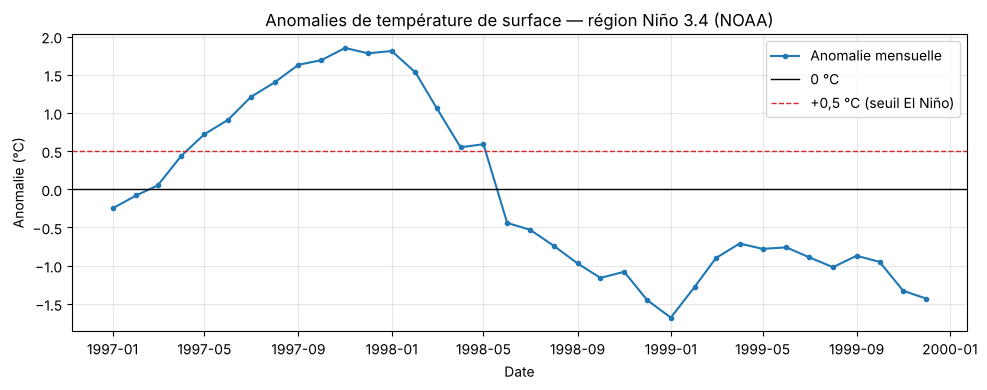

In [11]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(serie_finale.index, serie_finale.values, marker="o", ms=3, lw=1.5, label="Anomalie mensuelle")
ax.axhline(0, color="black", lw=1, label="0 °C")
ax.axhline(0.5, color="tab:red", ls="--", lw=1, label="+0,5 °C (seuil El Niño)")
ax.set_title("Anomalies de température de surface — région Niño 3.4 (NOAA)")
ax.set_xlabel("Date")
ax.set_ylabel("Anomalie (°C)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

In [12]:
au_dessus = serie_finale > 0.5
blocs = (au_dessus != au_dessus.shift()).cumsum()
for _, bloc in serie_finale[au_dessus].groupby(blocs[au_dessus]):
    print(f"> +0,5 °C de {bloc.index[0]:%Y-%m} à {bloc.index[-1]:%Y-%m} "
          f"({len(bloc)} mois, pic {bloc.max():+.2f} °C en {bloc.idxmax():%Y-%m})")

> +0,5 °C de 1997-05 à 1998-05 (13 mois, pic +1.85 °C en 1997-11)


**Réponses — Exercice 6**

1. **Anomalie positive** : l'eau de surface de la région Niño 3.4 est **plus chaude** que la normale
   climatologique du même mois (moyenne de référence) — tendance El Niño si elle persiste.
2. **Anomalie négative** : eau **plus froide** que la normale — tendance La Niña si elle persiste.
3. **Deux périodes d'anomalies élevées** : la montée de l'été-automne 1997 (+1,21 °C en juillet,
   +1,63 °C en septembre) culminant à **+1,85 °C en novembre 1997**, puis l'hiver 1997-98
   (+1,78 °C en décembre 1997, +1,81 °C en janvier 1998, +1,53 °C en février 1998). Au total les anomalies
   restent au-dessus de +0,5 °C pendant 13 mois consécutifs (mai 1997 → mai 1998) : c'est le grand
   El Niño 1997-98. À l'inverse, à partir de mi-1998 et jusqu'à fin 1999, les anomalies sont fortement
   négatives (minimum -1,68 °C en janvier 1999) : épisode La Niña.
4. **Non.** Un seul mois au-dessus de +0,5 °C peut être une fluctuation passagère. La définition
   opérationnelle de la NOAA (indice ONI) exige une **moyenne glissante sur 3 mois ≥ +0,5 °C pendant au moins
   5 saisons consécutives qui se chevauchent**, calculée avec sa propre climatologie de référence. Il faut donc
   une persistance dans le temps, pas une valeur ponctuelle.

### Exercice 7 — Variations mensuelles

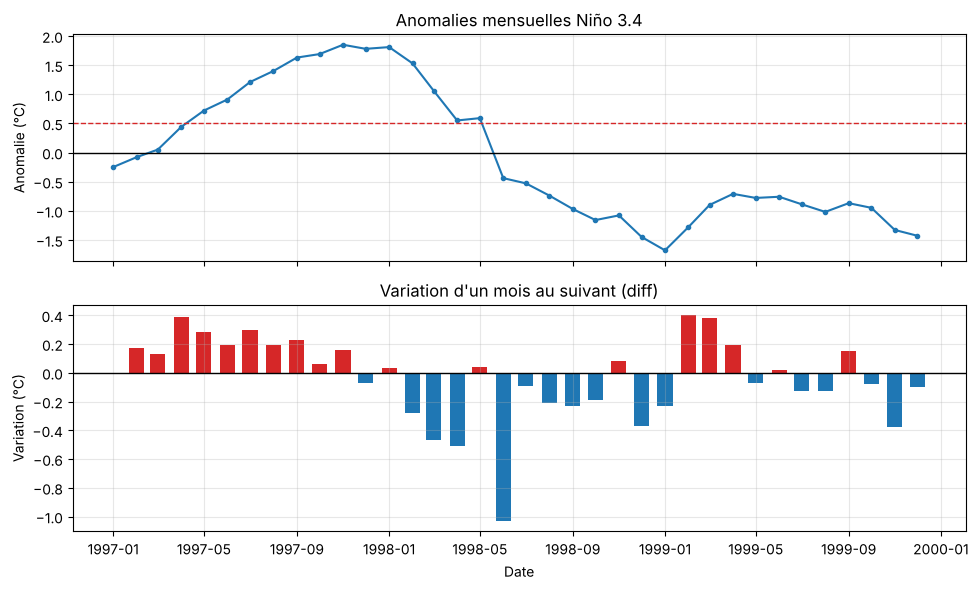

Plus forte hausse : +0.40 °C en 1999-02
Plus forte baisse : -1.03 °C en 1998-06
Mois avec anomalie > 0 mais variation < 0 : ['1997-12', '1998-02', '1998-03', '1998-04']


In [13]:
# La série est régulière (asfreq), donc diff() compare bien chaque mois au mois calendaire précédent
variation = serie_finale.diff()

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(serie_finale.index, serie_finale.values, marker="o", ms=3)
axes[0].axhline(0, color="black", lw=1)
axes[0].axhline(0.5, color="tab:red", ls="--", lw=1)
axes[0].set_title("Anomalies mensuelles Niño 3.4")
axes[0].set_ylabel("Anomalie (°C)")
axes[0].grid(alpha=0.3)

couleurs = np.where(variation.fillna(0) >= 0, "tab:red", "tab:blue")
axes[1].bar(variation.index, variation.values, width=20, color=couleurs)
axes[1].axhline(0, color="black", lw=1)
axes[1].set_title("Variation d'un mois au suivant (diff)")
axes[1].set_ylabel("Variation (°C)")
axes[1].set_xlabel("Date")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Plus forte hausse :", f"{variation.max():+.2f} °C en {variation.idxmax():%Y-%m}")
print("Plus forte baisse :", f"{variation.min():+.2f} °C en {variation.idxmin():%Y-%m}")
print("Mois avec anomalie > 0 mais variation < 0 :",
      list(serie_finale[(serie_finale > 0) & (variation < 0)].index.strftime("%Y-%m")))

**Réponses — Exercice 7**

- **Variation positive** : l'anomalie du mois est plus élevée que celle du mois précédent → l'eau se réchauffe
  relativement à la normale (que l'anomalie soit positive ou négative).
- **Anomalie positive ⇒ variation positive ? Non.** Le niveau et la pente sont deux choses différentes :
  en décembre 1997 (+1,78 °C) ou en février-avril 1998 (+1,53, +1,06, +0,55 °C), l'anomalie est encore
  positive mais diminue : El Niño est chaud mais en déclin. La plus forte baisse de l'extrait
  (-1,03 °C, de mai à juin 1998) marque la bascule vers La Niña.
- **Vérifier les mois avant `diff()`** : `diff()` soustrait la **ligne précédente**, pas le mois précédent.
  S'il manquait un mois, la « variation mensuelle » serait en réalité calculée sur deux mois (ou plus) sans
  que rien ne l'indique. Avec une série régulière (`asfreq('MS')`), un mois manquant devient NaN et la
  variation correspondante devient NaN : l'erreur est rendue visible au lieu d'être cachée.

### Exercice 8 — Distribution et moyenne mobile

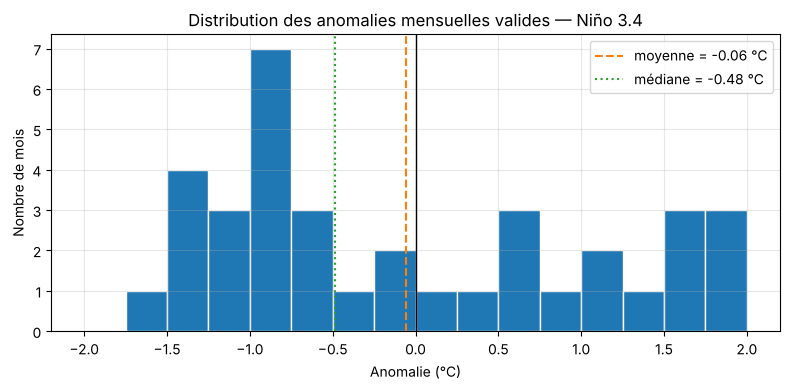

count    36.000000
mean     -0.057778
std       1.137097
min      -1.680000
25%      -0.955000
50%      -0.485000
75%       0.947500
max       1.850000
Name: anomalie, dtype: float64
Mois entre -0,5 et +0,5 °C : 5 / 36


In [14]:
valides = serie_finale.dropna()

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(valides, bins=np.arange(-2, 2.25, 0.25), edgecolor="white")
ax.axvline(0, color="black", lw=1)
ax.axvline(valides.mean(), color="tab:orange", ls="--", label=f"moyenne = {valides.mean():.2f} °C")
ax.axvline(valides.median(), color="tab:green", ls=":", label=f"médiane = {valides.median():.2f} °C")
ax.set_title("Distribution des anomalies mensuelles valides — Niño 3.4")
ax.set_xlabel("Anomalie (°C)")
ax.set_ylabel("Nombre de mois")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

print(valides.describe())
print("Mois entre -0,5 et +0,5 °C :", int(valides.between(-0.5, 0.5).sum()), "/", len(valides))

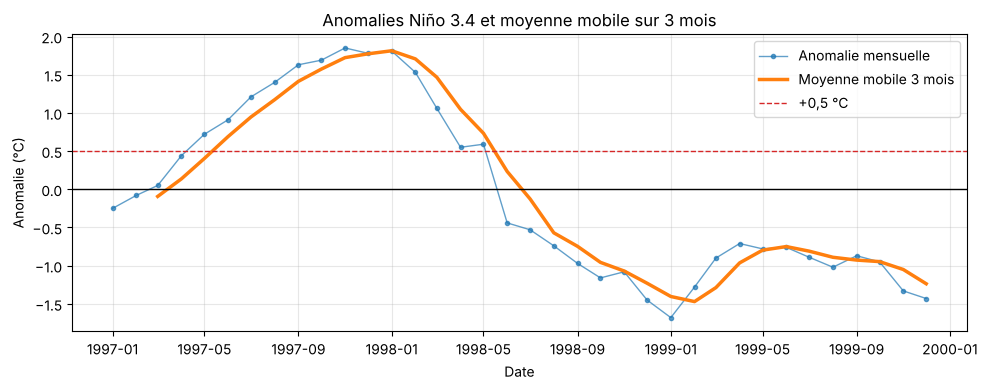

In [15]:
moyenne_mobile_3 = serie_finale.rolling(window=3, min_periods=3).mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(serie_finale.index, serie_finale.values, marker="o", ms=3, lw=1, alpha=0.7, label="Anomalie mensuelle")
ax.plot(moyenne_mobile_3.index, moyenne_mobile_3.values, lw=2.5, color="tab:orange", label="Moyenne mobile 3 mois")
ax.axhline(0, color="black", lw=1)
ax.axhline(0.5, color="tab:red", ls="--", lw=1, label="+0,5 °C")
ax.set_title("Anomalies Niño 3.4 et moyenne mobile sur 3 mois")
ax.set_xlabel("Date")
ax.set_ylabel("Anomalie (°C)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

**Réponses — Exercice 8**

1. **Concentrée autour de zéro ? Non**, pas sur cet extrait : seuls 5 mois sur 36 sont entre -0,5 et +0,5 °C
   (transitions). La distribution est **bimodale** : un groupe de valeurs entre +0,5 et +1,9 °C (El Niño 97-98)
   et un groupe plus fourni entre -0,7 et -1,7 °C (La Niña 98-99). La moyenne (≈ -0,06 °C) est proche de 0
   mais n'est pas représentative ; la médiane (≈ -0,49 °C) est tirée vers le négatif car La Niña occupe plus de
   mois. Sur 3 ans choisis autour d'un épisode majeur, on ne peut pas généraliser à toute la série.
2. **Valeurs extrêmes ?** Les valeurs les plus fortes (+1,85 °C en novembre 1997, -1,68 °C en janvier 1999)
   sont élevées mais **réelles et physiquement cohérentes** (1997-98 est l'un des plus forts El Niño du
   XXᵉ siècle) : ce ne sont pas des erreurs, on ne les supprime pas. Aucune valeur aberrante de type code
   manquant n'est présente.
3. **Intérêt de la moyenne mobile** : lisser le bruit mensuel pour faire ressortir la tendance de fond et la
   persistance d'un épisode (c'est aussi le principe de l'ONI, qui utilise une moyenne sur 3 mois).
4. **Elle masque les variations rapides** car chaque point est la moyenne de 3 mois : un pic ou une chute brutale
   est étalé et atténué (en novembre 1997, +1,85 °C devient +1,72 °C) et la courbe est décalée dans le temps
   (fenêtre « en arrière » : le maximum lissé, +1,81 °C, n'apparaît qu'en janvier 1998). La chute de mai-juin 1998
   apparaît ainsi plus progressive qu'elle ne l'est.

> Cette moyenne mobile est pédagogique : ce n'est **pas** l'indice ONI officiel (qui utilise ERSSTv5,
> une climatologie glissante de 30 ans et une règle de 5 saisons consécutives).

## Partie 4 — Validation et exportation

### Exercice 9 — Contrôler les données préparées

In [16]:
donnees_propres = pd.DataFrame({
    "date": serie_finale.index,
    "anomalie": serie_finale.values,
    "variation": variation.values,
    "moyenne_mobile_3": moyenne_mobile_3.values,
    "interpole": isole.reindex(serie_finale.index, fill_value=False).values,
}).round({"anomalie": 2, "variation": 2, "moyenne_mobile_3": 3})

# Assertions de contrôle
assert donnees_propres["date"].is_monotonic_increasing, "Les dates ne sont pas en ordre chronologique"
assert not donnees_propres["date"].duplicated().any(), "Il reste des dates répétées"
assert not (donnees_propres["anomalie"] == CODE_MANQUANT).any(), "Le code -9999.0 est encore présent"
assert (donnees_propres["anomalie"].dropna() > -90).all(), "Valeur aberrante assimilable à un code manquant"
assert donnees_propres["date"].diff().dropna().dt.days.between(28, 31).all(), "La série mensuelle n'est pas continue"
assert len(donnees_propres) == len(pd.date_range(donnees_propres["date"].min(),
                                                 donnees_propres["date"].max(), freq="MS"))
assert list(donnees_propres.columns[:4]) == ["date", "anomalie", "variation", "moyenne_mobile_3"]
print("Toutes les assertions sont validées ✅")

donnees_propres.info()
donnees_propres.head(6)

Toutes les assertions sont validées ✅
<class 'pandas.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   date              36 non-null     datetime64[us]
 1   anomalie          36 non-null     float64       
 2   variation         35 non-null     float64       
 3   moyenne_mobile_3  34 non-null     float64       
 4   interpole         36 non-null     bool          
dtypes: bool(1), datetime64[us](1), float64(3)
memory usage: 1.3 KB


,date,anomalie,variation,moyenne_mobile_3,interpole
0,1997-01-01,-0.25,NaN,NaN,False
1,1997-02-01,-0.08,0.17,NaN,False
2,1997-03-01,0.05,0.13,-0.093,False
3,1997-04-01,0.44,0.39,0.137,False
4,1997-05-01,0.72,0.28,0.403,False
5,1997-06-01,0.91,0.19,0.690,False


Les NaN restants sont **volontaires** : la 1re valeur de `variation` (pas de mois précédent) et les 2 premières
valeurs de `moyenne_mobile_3` (fenêtre incomplète). Ils ne doivent pas être remplacés : aucune donnée ne permet
de les calculer.

### Exercice 10 — Exporter et vérifier

In [17]:
donnees_propres.to_csv("noaa_nino34_propre.csv", index=False)

relu = pd.read_csv("noaa_nino34_propre.csv", parse_dates=["date"])

assert relu.shape == donnees_propres.shape, "Nombre de lignes/colonnes différent après rechargement"
assert relu["date"].equals(donnees_propres["date"]), "Dates différentes après rechargement"
for col in ["anomalie", "variation", "moyenne_mobile_3"]:
    assert np.allclose(relu[col], donnees_propres[col], equal_nan=True), f"Valeurs différentes : {col}"
    assert relu[col].isna().sum() == donnees_propres[col].isna().sum()

print("Rechargement cohérent ✅  —", relu.shape[0], "lignes,", relu.shape[1], "colonnes")
print(relu[["anomalie", "variation", "moyenne_mobile_3"]].agg(["count", "mean", "min", "max"]).round(3))

Rechargement cohérent ✅  — 36 lignes, 5 colonnes
       anomalie  variation  moyenne_mobile_3
count    36.000     35.000            34.000
mean     -0.058     -0.034            -0.014
min      -1.680     -1.030            -1.470
max       1.850      0.400             1.813


## Conclusion

Le diagnostic a montré un extrait propre (36 mois continus de 1997-01 à 1999-12, sans NaN, sans `-9999.0`,
sans doublon), mais lu avec des dates en texte : il a fallu convertir les dates et les valeurs, vérifier
explicitement l'absence des codes manquants et la continuité mensuelle, trier et régulariser la série (`asfreq`)
avant de calculer `diff()` et la moyenne mobile. Aucune valeur n'a été interpolée ni supprimée ; les seuls NaN
du fichier final sont structurels (1re variation, 2 premières moyennes mobiles), et sur le fichier complet de la
NOAA les `-9999.0` de fin de série deviennent des NaN puis sont exclus de la période analysée.

**Question finale — un fichier sans NaN est-il fiable ?** Non. L'absence de NaN peut cacher des codes
sentinelles (`-9999.0` est un nombre « valide »), des mois entièrement absents, des doublons ou des dates
en conflit, un mauvais ordre chronologique, ou pire des NaN remplacés par des valeurs inventées (interpolation
abusive, remplissage par 0 ou par la moyenne). La fiabilité vient des contrôles effectués et des décisions
documentées, pas du simple comptage des NaN.